# Лабораторная работа 2

## Полносвязная нейронная сеть

Реализовать нейронную сеть, состоящую из двух полносвязных слоев и решающую задачу классификации на наборе данных из лабораторной работы 1.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scripts.data_utils import load_CIFAR10

from scripts.classifiers.neural_net import TwoLayerNet

%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0)
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'


def rel_error(x, y):
    """ returns relative error """
    return np.max(np.abs(x - y) / np.maximum(1e-8, np.abs(x) + np.abs(y)))

1. Добавьте реализации методов класса TwoLayerNet . Проверьте вашу реализацию на модельных данных (Код приведен ниже).  

In [2]:
input_size = 4
hidden_size = 10
num_classes = 3
num_inputs = 5

def init_toy_model():
    np.random.seed(0)
    return TwoLayerNet(input_size, hidden_size, num_classes, std=1e-1)

def init_toy_data():
    np.random.seed(1)
    X = 10 * np.random.randn(num_inputs, input_size)
    y = np.array([0, 1, 2, 2, 1])
    return X, y

net = init_toy_model()
X, y = init_toy_data()

# Прямой проход: вычисление выхода сети

Реализуйте первую часть  метода TwoLayerNet.loss, вычисляющую оценки классов для входных данных. 

Сравните ваш выход сети с эталонными значениями. Ошибка должна быть очень маленькой (можете ориентироваться на значение < 1e-7) .

In [3]:
scores = net.loss(X)
print('Your scores:')
print(scores)
print()
print('correct scores:')
correct_scores = np.asarray([
  [-0.81233741, -1.27654624, -0.70335995],
  [-0.17129677, -1.18803311, -0.47310444],
  [-0.51590475, -1.01354314, -0.8504215 ],
  [-0.15419291, -0.48629638, -0.52901952],
  [-0.00618733, -0.12435261, -0.15226949]])
print(correct_scores)
print()


print('Difference between your scores and correct scores:')
print(np.sum(np.abs(scores - correct_scores)))

Your scores:
[[-0.81233741 -1.27654624 -0.70335995]
 [-0.17129677 -1.18803311 -0.47310444]
 [-0.51590475 -1.01354314 -0.8504215 ]
 [-0.15419291 -0.48629638 -0.52901952]
 [-0.00618733 -0.12435261 -0.15226949]]

correct scores:
[[-0.81233741 -1.27654624 -0.70335995]
 [-0.17129677 -1.18803311 -0.47310444]
 [-0.51590475 -1.01354314 -0.8504215 ]
 [-0.15419291 -0.48629638 -0.52901952]
 [-0.00618733 -0.12435261 -0.15226949]]

Difference between your scores and correct scores:
3.680272120387684e-08



# Прямой проход: вычисление loss

Реализуйте вторую часть метода, вычисляющую значение функции потерь. Сравните с эталоном. Ошибка должна быть очень маленькой (можете ориентироваться на значение < 1e-12) .

In [4]:
loss, _ = net.loss(X, y, reg=0.05)
correct_loss = 1.30378789133

print('Difference between your loss and correct loss:')
print(np.sum(np.abs(loss - correct_loss)))

Difference between your loss and correct loss:
1.7985612998927536e-13


# Обратный проход

Реализуйте третью часть метода loss. Используйте численную реализацию расчета градиента для проверки вашей реализации обратного прохода.  Если прямой и обратный проходы реализованы верно, то ошибка будет < 1e-8 для каждой из переменных W1, W2, b1, и b2. 


In [5]:
from scripts.gradient_check import eval_numerical_gradient

loss, grads = net.loss(X, y, reg=0.05)

for param_name in grads:
    f = lambda W: net.loss(X, y, reg=0.05)[0]
    param_grad_num = eval_numerical_gradient(f, net.params[param_name], verbose=False)
    print('%s max relative error: %e' % (param_name, rel_error(param_grad_num, grads[param_name])))

W2 max relative error: 3.440708e-09
b2 max relative error: 3.865112e-11
W1 max relative error: 3.561318e-09
b1 max relative error: 2.738420e-09


# Обучение нейронной сети на смоделированных данных

Реализуйте методы TwoLayerNet.train и TwoLayerNet.predict. Обучайте сеть до тех пор, пока значение loss не будет < 0.02.


iteration 0 / 305: loss 1.241994
iteration 100 / 305: loss 0.015891
iteration 200 / 305: loss 0.014784
iteration 300 / 305: loss 0.013544
Final training loss:  0.013739061311945912


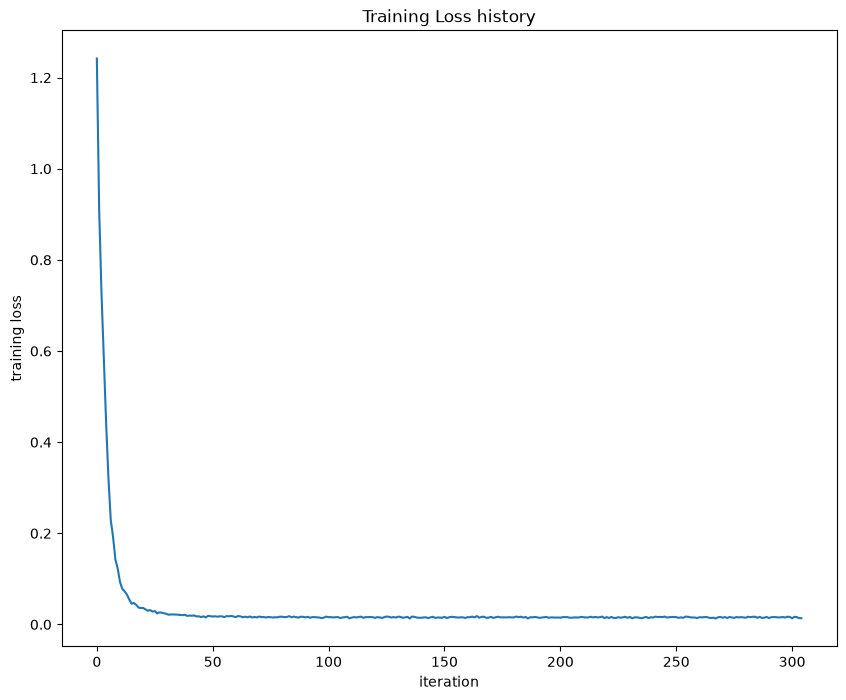

In [6]:
net = init_toy_model()
stats = net.train(X, y, X, y,
            learning_rate=1e-1, reg=5e-6,
            num_iters=305, verbose=True)

print('Final training loss: ', stats['loss_history'][-1])

plt.plot(stats['loss_history'])
plt.xlabel('iteration')
plt.ylabel('training loss')
plt.title('Training Loss history')
plt.show()

# Обучение нейронной сети на реальном наборе данных (CIFAR-10, MNIST)

Загрузите набор данных, соответствующий вашему варианту. 

Разделите данные на обучающую, тестовую и валидационную выборки.

Выполните предобработку данных, как в ЛР 1. 

Обучите нейронную сеть на ваших данных. 

При сдаче лабораторной работы объясните значения всех параметров метода train.

In [7]:
cifar10_dir = 'scripts/datasets/cifar-10-batches-py'

try:
   del X_train, y_train
   del X_test, y_test
   print('Clear previously loaded data.')
except:
   pass

X_train, y_train, X_test, y_test = load_CIFAR10(cifar10_dir)

print('Training data shape: ', X_train.shape)
print('Training labels shape: ', y_train.shape)
print('Test data shape: ', X_test.shape)
print('Test labels shape: ', y_test.shape)

Training data shape:  (50000, 32, 32, 3)
Training labels shape:  (50000,)
Test data shape:  (10000, 32, 32, 3)
Test labels shape:  (10000,)


In [8]:
X_all = X_train.reshape(len(X_train), -1).astype(np.float32)
y_all = y_train.copy()
X_test = X_test.reshape(len(X_test), -1).astype(np.float32)
y_test = y_test.copy()

X_train = X_all[:40000].copy()
y_train = y_all[:40000].copy()
X_val = X_all[40000:].copy()
y_val = y_all[40000:].copy()

X_dev = X_train.copy()
y_dev = y_train.copy()

print('Размер обучающей выборки:', X_train.shape, y_train.shape)
print('Размер валидационной выборки:', X_val.shape, y_val.shape)
print('Размер тестовой выборки:', X_test.shape, y_test.shape)
print('Размер выборки для проверки функций:', X_dev.shape, y_dev.shape)

Размер обучающей выборки: (40000, 3072) (40000,)
Размер валидационной выборки: (10000, 3072) (10000,)
Размер тестовой выборки: (10000, 3072) (10000,)
Размер выборки для проверки функций: (40000, 3072) (40000,)


[130.89912 136.1391  132.54753 130.2976  135.49132 131.80087 131.2357
 136.31682 132.54535 131.7664 ]


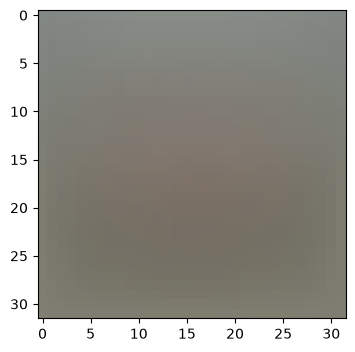

(40000, 3072) (10000, 3072) (10000, 3072)


In [9]:
mean_image = np.mean(X_train, axis=0)
print(mean_image[:10]) 
plt.figure(figsize=(4,4))
plt.imshow(mean_image.reshape((32,32,3)).astype('uint8')) 
plt.show()

X_train -= mean_image
X_val -= mean_image
X_test -= mean_image
X_dev -= mean_image

print(X_train.shape, X_val.shape, X_test.shape)

In [12]:
input_size = X_train.shape[1]
num_classes = int(max(np.max(y_train), np.max(y_val), np.max(y_test))) + 1

experiments = [
    # {'hidden_size': 50, 'learning_rate': 1e-4, 'reg': 0.25},
    # {'hidden_size': 100, 'learning_rate': 1e-3, 'reg': 0.1},
    # {'hidden_size': 100, 'learning_rate': 1e-4, 'reg': 0.25},
    # {'hidden_size': 128, 'learning_rate': 1e-3, 'reg': 0.1},
    # {'hidden_size': 256, 'learning_rate': 1e-3, 'reg': 0.1, 'rate_decay': 0.95},
    # {'hidden_size': 256, 'learning_rate': 1e-3, 'reg': 0.1, 'rate_decay': 0.95, 'batch_size': 300},
    {'hidden_size': 512, 'learning_rate': 1e-3, 'reg': 0.1, 'rate_decay': 0.95, 'batch_size': 300},
]
best_val_acc = -1

for params in experiments:
    model = TwoLayerNet(input_size, params['hidden_size'], num_classes)
    history = model.train(
        X_train, y_train, X_val, y_val,
        num_iters=3000, batch_size=params['batch_size'],
        learning_rate=params['learning_rate'],
        learning_rate_decay=params['rate_decay'], reg=params['reg'], verbose=True
    )
    accuracy = (model.predict(X_val) == y_val).mean()
    print('Параметры:', params, 'Validation accuracy:', accuracy)
    if accuracy > best_val_acc:
        best_val_acc, best_net, best_stats = accuracy, model, history

net, stats = best_net, best_stats
test_acc = (net.predict(X_test) == y_test).mean()
print('Best validation accuracy:', best_val_acc)
print('Test accuracy:', test_acc)

iteration 0 / 3000: loss 2.304166
iteration 100 / 3000: loss 1.851430
iteration 200 / 3000: loss 1.701464
iteration 300 / 3000: loss 1.604386
iteration 400 / 3000: loss 1.589129
iteration 500 / 3000: loss 1.484143
iteration 600 / 3000: loss 1.569179
iteration 700 / 3000: loss 1.455036
iteration 800 / 3000: loss 1.428443
iteration 900 / 3000: loss 1.497305
iteration 1000 / 3000: loss 1.380431
iteration 1100 / 3000: loss 1.410081
iteration 1200 / 3000: loss 1.307361
iteration 1300 / 3000: loss 1.329403
iteration 1400 / 3000: loss 1.298859
iteration 1500 / 3000: loss 1.292676
iteration 1600 / 3000: loss 1.252360
iteration 1700 / 3000: loss 1.248551
iteration 1800 / 3000: loss 1.257050
iteration 1900 / 3000: loss 1.147473
iteration 2000 / 3000: loss 1.148972
iteration 2100 / 3000: loss 1.088624
iteration 2200 / 3000: loss 1.210018
iteration 2300 / 3000: loss 1.181449
iteration 2400 / 3000: loss 1.126582
iteration 2500 / 3000: loss 1.158927
iteration 2600 / 3000: loss 1.133720
iteration 270

Используя параметры по умолчанию, вы можете получить accuracy, примерно равный 0.29. 

Проведите настройку гиперпараметров для увеличения accuracy. Поэкспериментируйте со значениями гиперпараметров, например, с количеством скрытых слоев, количеством эпох, скорости обучения и др. Ваша цель - максимально увеличить accuracy полносвязной сети на валидационном наборе. Различные эксперименты приветствуются. Например, вы можете использовать методы для сокращения размерности признакового пространства (например, PCA), добавить dropout слои и др. 

Для лучшей модели вычислите acсuracy на тестовом наборе. 

Для отладки процесса обучения часто помогают графики изменения loss и accuracy в процессе обучения. Ниже приведен код построения таких графиков. 

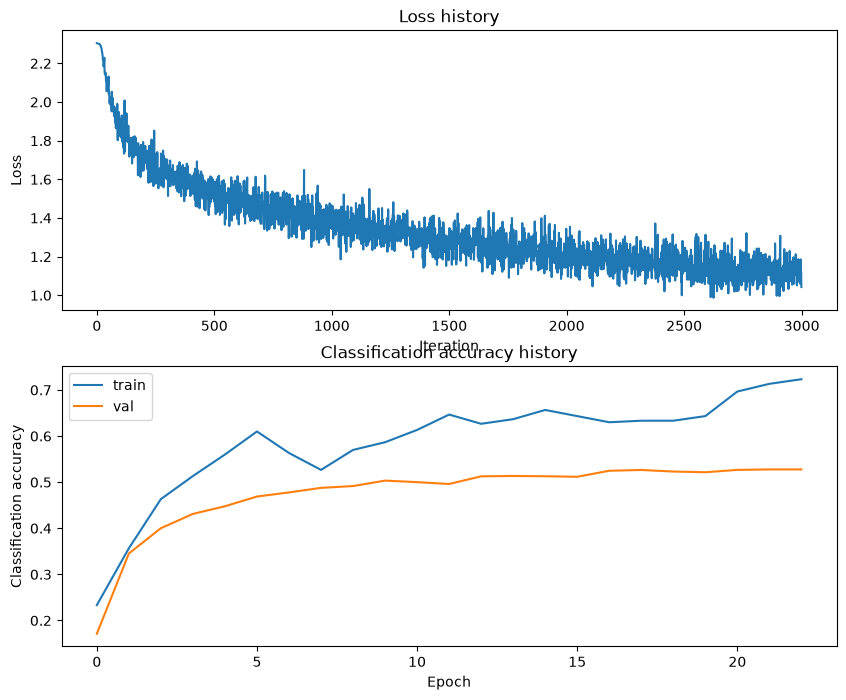

In [13]:
plt.subplot(2, 1, 1)
plt.plot(stats['loss_history'])
plt.title('Loss history')
plt.xlabel('Iteration')
plt.ylabel('Loss')

plt.subplot(2, 1, 2)
plt.plot(stats['train_acc_history'], label='train')
plt.plot(stats['val_acc_history'], label='val')
plt.title('Classification accuracy history')
plt.xlabel('Epoch')
plt.ylabel('Classification accuracy')
plt.legend()
plt.show()

In [14]:
net.params['W1']

array([[ 6.40053456e-04, -6.99060877e-04,  1.18541993e-04, ...,
        -2.87892558e-05, -6.36984757e-04,  4.30203306e-04],
       [ 8.76354571e-04, -9.51449908e-05,  5.82490422e-04, ...,
        -4.41865111e-04, -1.13623883e-05,  1.57385355e-04],
       [ 2.46158020e-04,  4.23229865e-04,  1.95522310e-04, ...,
        -1.78646807e-03,  2.27380691e-03,  2.93590269e-04],
       ...,
       [ 9.36566493e-05, -3.91458034e-04,  7.73864127e-04, ...,
        -3.37131989e-04, -9.20725260e-04, -1.47498403e-04],
       [ 1.22468661e-04, -1.53921178e-03,  1.06904103e-03, ...,
         4.17377796e-04, -1.42337553e-03, -8.23791771e-07],
       [ 3.60952151e-04, -1.68717807e-03,  5.80918264e-04, ...,
        -1.80118388e-04, -7.06559742e-04,  4.28859612e-04]],
      shape=(3072, 512))

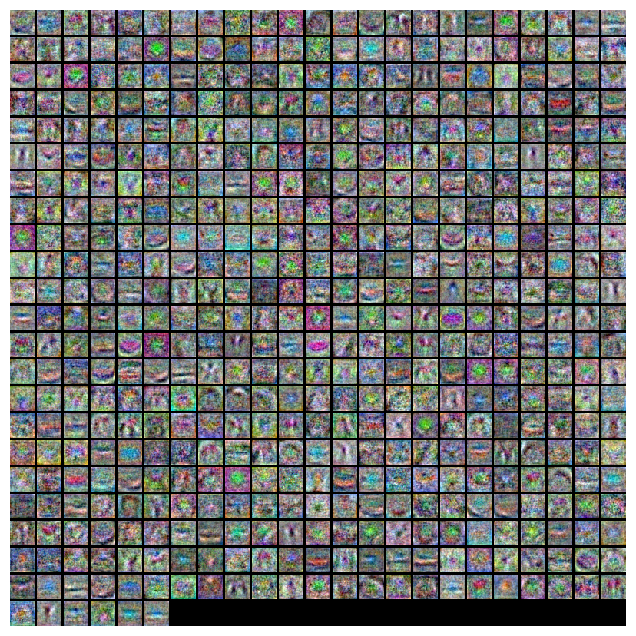

In [15]:
from scripts.vis_utils import visualize_grid

def show_net_weights(net):
    W1 = net.params['W1']
    W1 = W1.reshape(32, 32, 3, -1).transpose(3, 0, 1, 2)
    plt.imshow(visualize_grid(W1, padding=3).astype('uint8'))
    plt.gca().axis('off')
    plt.show()

show_net_weights(net)

В ходе работы реализована двухслойная полносвязная нейронная сеть с ReLU и softmax. Проверены прямой проход, функция потерь и градиенты.

Для реального набора данных предусмотрены сравнение нескольких наборов гиперпараметров, выбор модели по validation accuracy и итоговая оценка на тестовой выборке.

Итого, лучший результат получился с гиперпараметрами      
   
`{'hidden_size': 512, 'learning_rate': 1e-3, 'reg': 0.1, 'rate_decay': 0.95, 'batch_size': 300}`

с accuracy = 0.5729 (на тестовой выборке)